# Programming Assignment 2, IT 540: Random Forest

### 80 points + 6 possible extra credit

 PLEASE READ EVERY SINGLE COMMENT IN THIS FILE. 
 
 **Before doing anything else, make a copy of this file, add your name to the filename, and work with the copy. That way, if you make a serious error you can view the original that is still on your computer.**


 In what follows, it should be clear where you should place YOUR code. For example, if you see something like this:
 
 #### someVariable = # Finish this line of code
 
 then you need to replace the comment portion with executable Python code, for example:
 
 #### someVariable = 5

 IMPORTANT:  Make sure THIS code file is in the same directory
             as where your input data is.  If you do not, then you will get
             an error message when you try to read in your data.

 When you read your data in, it matters whether your data has a header
 row or not. If it's a header row that contains column names instead of data values, then pandas needs to know it's a header in order to (a) display it properly, and (b) make the correct computations with it.
 
 The default for pd.read_csv is such that pandas will attempt to infer whether there is a header or not. (Very useful, right?) It usually works correct, but if you get weird results, you'll need to inform pandas explicity if there is a header row or not. We will see that in another assignment.
 

In [2]:
# Run this cell to load the packages that you need for this assignment.
# If you get an error message telling you that the module does not exist
# then you will need to install it into the Anaconda environment you 
# created for this class, and then re-run this cell.

import matplotlib.pyplot as plt
import numpy             as np
import pandas            as pd

import sklearn
from   sklearn.ensemble        import RandomForestClassifier
from   sklearn.metrics         import confusion_matrix, ConfusionMatrixDisplay
from   sklearn.model_selection import train_test_split
from   urllib.request          import urlretrieve

%matplotlib inline


In [3]:
# Task 1. 4 points + 3 points extra credit

# Get the data from:
# http://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data
# You can do that manually, if you wish.  If you want 3 additional points of
# extra credit, you can figure out a way to do it programmatically in Python.
# Google is your friend if you don't know how to do that.

# Put the dataset into the same location as your code file (this notebook file)

# A description of the dataset may be found at:
# http://archive.ics.uci.edu/ml/datasets/Heart+Disease

# It is extremely important to read such descriptions, which can often
# inform you of peculiarities of the data that you may need to change
# before performing an analysis, or whether or not the data file contains
# a header line that has the names of the variables (columns).

################## Put your code below ##################
 #Extra credit: Download the file programmatically
url = 'http://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data'
filename = 'processed.cleveland.data'

# Download the file
urlretrieve(url, filename)
print(f"Data downloaded successfully to {filename}")

Data downloaded successfully to processed.cleveland.data


In [4]:
### Task 2. 6 points. Read your data into a variable and display it.

# 3 points for setting heartData
# 3 points for displaying the dataframe

# Make sure you treat the existence of a header (or lack of) correctly
# Before you continue, take a look at the documentation for pd.read_csv at:
# https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_csv.html
# Scroll down for the discussion of the argument called 'header'
# Notice that it says the default value is 'infer'. In Assignment 1
# since we did not change the default, that is the value that was used.
# Infer means that Pandas will try to determine automatically if the first
# row contains headers or not, and pandas does a pretty good job of it.
# In Asssignment 1 it does detect that a header row existed.
# Let's use the same value here, but this time make it explicit by
# adding header='infer' in the call to pd.read_csv

heartData = pd.read_csv('processed.cleveland.data', header='infer')

# Now 'display' the dataframe to the screen to see if it does
# contain a header row of column names, or if it simply shows
# the top row as data that looks like all the other rows.

display(heartData)


,63.0,1.0,1.0.1,145.0,233.0,1.0.2,2.0,150.0,0.0,2.3,3.0,0.0.1,6.0,0
0,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
1,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
2,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
3,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
4,56.0,1.0,2.0,120.0,236.0,0.0,0.0,178.0,0.0,0.8,1.0,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
297,45.0,1.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,2.0,0.0,7.0,1
298,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,2.0,2.0,7.0,2
299,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,2.0,1.0,7.0,3
300,57.0,0.0,2.0,130.0,236.0,0.0,2.0,174.0,0.0,0.0,2.0,1.0,3.0,1


##### If you did that correctly, you should now see the following at the bottom of the cell's output:

302 rows × 14 columns

You should also be able to see that there is not a header row. There are actually 303 rows of data, but pandas INCORRECTLY inferred that the first row of data is a header. You can see that directly if you simply go to the data file on your computer and open it up with a text file application like Notepad on Windows or TextEdit on a Mac.  Do that and you will clearly see there is no header.  

Pandas can and does make mistakes!  So now we need to read in the data a second time and make sure that we tell it to treat the first row as data.



In [5]:
# Task 3: 4 points
# 3 points for the correct read_csv and
# 1 point for the display.

# Read in the data, telling pandas to treat the first row as data.
# Read the pandas documentation CAREFULLY and you will see that there
# is a specific value for header=  when you need to tell it that
# there are no header names.  Use that value here.
# After reading in the data, again use 'display' to show the
# data and you'll see how pandas now simply uses integers
# as column names.
# In the next assignment you will learn how to manually replace 
# these automatically supplied variable names with more meaningful ones.

heartData = pd.read_csv('processed.cleveland.data', header=None)

display(heartData)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45.0,1.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,2.0,0.0,7.0,1
299,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,2.0,2.0,7.0,2
300,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,2.0,1.0,7.0,3
301,57.0,0.0,2.0,130.0,236.0,0.0,2.0,174.0,0.0,0.0,2.0,1.0,3.0,1


##### Now you should see this in the cell's output:

303 rows × 14 columns

If you don't see that, then you did something wrong.

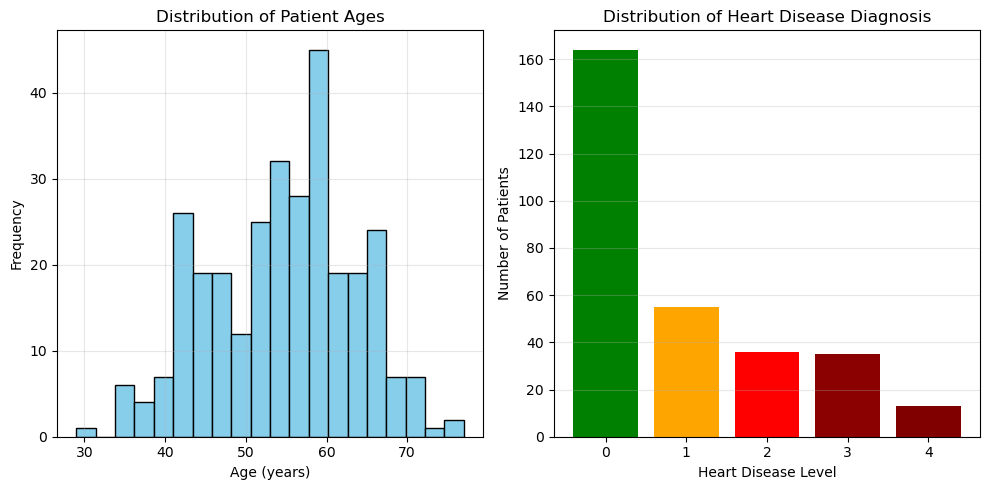

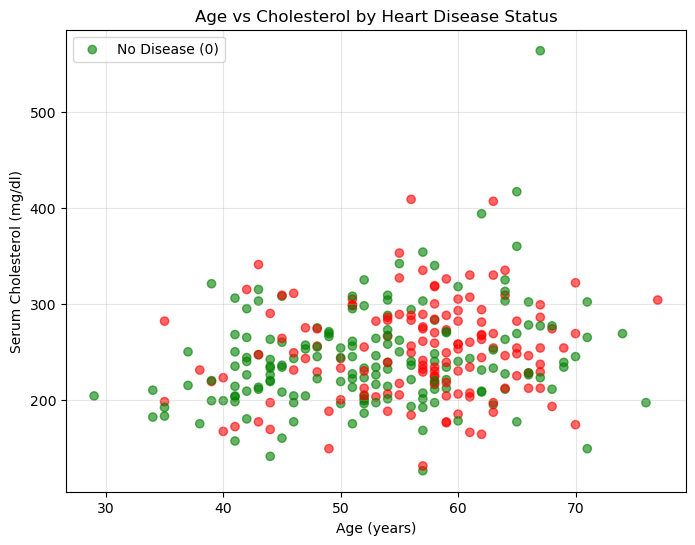

In [6]:
# Task 4. 12 points 

# Add some additional code to do some data visualization.
# Create AT LEAST TWO matplotib plots (more than 2 is also good).
# For example you could do:
# # a bar plot, scatter plot, histogram, box plot, etc.

# Of course, you'll need to either import them from 
# matplotlib or reference them directly in your code.

# Try to make each plot visually pleasing with the use of
# colors, but MOST importantly you should ALWAYS include
# labels for your x and y axes so we know what we are looking
# at, and a main title for the graph at the top (or bottom).
# In the corporate world, and even in the world of research,
# I have seen people called out by their 'superiors' for not
# including such labels/titles and also units (where applicable).

# HINT:  Some of the rows of data contain missing values for 1 or more
# of the columns.  Can you discover how that is represented in the data?
# Make sure you read the rest of my comments in the next cell.


# -- put your exploratory code below on multiple lines ---

# Plot 1: Histogram of Age Distribution (column 0)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.hist(heartData[0], bins=20, color='skyblue', edgecolor='black')
plt.xlabel('Age (years)')
plt.ylabel('Frequency')
plt.title('Distribution of Patient Ages')
plt.grid(True, alpha=0.3)

# Plot 2: Bar plot of Heart Disease Presence (column 13)
plt.subplot(1, 2, 2)
disease_counts = heartData[13].value_counts().sort_index()
plt.bar(disease_counts.index, disease_counts.values, color=['green', 'orange', 'red', 'darkred', 'maroon'])
plt.xlabel('Heart Disease Level')
plt.ylabel('Number of Patients')
plt.title('Distribution of Heart Disease Diagnosis')
plt.xticks(range(5))
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

# Additional visualization: Scatter plot of Age vs Cholesterol
plt.figure(figsize=(8, 6))
colors = ['green' if x == 0 else 'red' for x in heartData[13]]
plt.scatter(heartData[0], heartData[4], c=colors, alpha=0.6)
plt.xlabel('Age (years)')
plt.ylabel('Serum Cholesterol (mg/dl)')
plt.title('Age vs Cholesterol by Heart Disease Status')
plt.legend(['No Disease (0)', 'Disease (1-4)'])
plt.grid(True, alpha=0.3)
plt.show()








#### If you carefully read the dataset's documentation you would have noticed that there is some missing data buried in two of the columns. And if you go back and look at Task 3's output, you will notice that a question mark '?' is used to represent missing data. For example, look at column 11 in the very last row. Missing data is not uncommon in real datasets, and you'll have to decide how to deal with it.

#### One common method is simply to delete all rows with any missing data.

In [7]:
# Task 5, 8 points:  Dealing with missing data.

# 3 points: Tell pandas that '?' means NaN and redisplay
# 2 points: Delete all rows with missing data.
# 3 points: Drop missing data, save clean data and redisplay

# Since there is missing data in some of these rows, 
# let's delete those rows before doing any analysis.

# BEFORE you do that, read the data in yet again and use 
# parameter na_values="?" to inform pandas that the question mark 
# represents missing data in this file.

# After reading it again, display it again to verify that the
# the '?' has been converted to NaN (not a number), one of the standard
# ways to represent missing data in Python.

heartData = pd.read_csv('processed.cleveland.data', header=None, na_values="?")

display(heartData)

# Now you can simply tell pandas to drop all rows that include missing data
# by using the dropna() method of the dataframe and resaving the result
# into a new variable called 'heartDataClean'.  Do that and then display  
# the new dataframe.

heartDataClean = heartData.dropna()
display(heartDataClean)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45.0,1.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,2.0,0.0,7.0,1
299,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,2.0,2.0,7.0,2
300,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,2.0,1.0,7.0,3
301,57.0,0.0,2.0,130.0,236.0,0.0,2.0,174.0,0.0,0.0,2.0,1.0,3.0,1


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
297,57.0,0.0,4.0,140.0,241.0,0.0,0.0,123.0,1.0,0.2,2.0,0.0,7.0,1
298,45.0,1.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,2.0,0.0,7.0,1
299,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,2.0,2.0,7.0,2
300,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,2.0,1.0,7.0,3


#### You should now be able to see that row 302 has been dropped, and that the last row is now 301. You should also see at the bottom that there are only 297 rows instead of the original 303. However, before we can continue, there is one more thing we need to do with this data


In [8]:
# Look at the above display again at variable 13, which, and I'm sure you already 
# know this because you previously read the data description, is what we are trying
# to predict. 

# Further notice that variable 13 contains integers.
# And again, since you previously read the data documentation carefully,
# you will remember that it told you that 'The "goal" field refers to the presence of heart disease in the patient. 
# It is integer valued from 0 (no presence) to 4'.

# In other words, instead of all 5 integers we only care about "0" (heart disease) vs.
# the other four values.  So let us change those other values 1-4 to all be 1.
# Then our classifier will just try to predict 0 or 1, which is what we want.
# The code below makes that change.

# We use heartDataClean.loc[:, 13].clip(upper=1) which does the following:
# It looks at all rows of column 13.  It compares the value on each row
# to the value 1.  If any value is greater than one (i.e. upper), then it
# changes that value to be the threshold of 1. Therefore, the clip
# does not change the zeros or the ones, but it does change the values of
# 2, 3 or 4 and sets them to 1.  If we had used clip(upper=2) then it would
# have changed only the 3 and 4 values to be 2.

# Without the next line of code the clippedValues code generates a warning
# Per: https://stackoverflow.com/questions/20625582/how-to-deal-with-settingwithcopywarning-in-pandas 
# This warning is likely a false positive, hence the next line of code simply disables the warning.

pd.options.mode.chained_assignment = None 

clippedValues             = heartDataClean.loc[:, 13].clip(upper=1)
heartDataClean.loc[:, 13] = clippedValues

heartDataClean


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
297,57.0,0.0,4.0,140.0,241.0,0.0,0.0,123.0,1.0,0.2,2.0,0.0,7.0,1
298,45.0,1.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,2.0,0.0,7.0,1
299,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,2.0,2.0,7.0,1
300,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,2.0,1.0,7.0,1


#### As you can in the cell output, the 2's, 3's and 4's have all been changed to 1. Now let's finish getting our data ready so we can build some tree models!

In [9]:
# Task 6: 10 points
# Split data into training and test sets

# We will use 70% of the data for training and 30% for testing. 
# Also, we want to select the training data RANDOMLY.

# Fortunately, the good people who brought us scikit-learn have already 
# written a function for us that can do all that and more: train_test_split
# https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html 
# Unless you already know how to use it, go to that URL, and learn how.

# You will need to give the predictor features of heartDataClean
# as the first argument of train_test_split, and the last feature 
# of heartDataClean as the second argument.
# You will also need to tell it to use 70% of the data for training
# and 30% for test. There are two different ways to do that, both 
# of which are super easy. Just look at the example given in the
# scikit-learn documentation and choose one of the two.

# When choosing data randomly, it's also a GOOD idea to do it in
# a repeatable fashion. That means if you run the same code again
# you'll get the same data, even though it's selected randomly.
# How is that even possible, you may wonder. If it's repeatable,
# then it's clearly not done randomly. That's true, so it's more proper
# to describe this as a pseudo-random process.  It's VERY common in 
# data science, and it's done by setting what is called a random seed.
# In scikit-learn the random seed is performed with a modeling parameter
# called 'random_state' which you set to some arbitrary integer.
# You use it like this: 
# someFunction(argument1, argument2, random_state=someInteger, 
#                                    otherKeywordArgument=otherValue)

# There are two reasons for doing this:
# 1. It helps YOU during development because you'd like to use the identical dataset every 
#    time you run your code so you can expect to see the identical results each time.
#    Without a random seed, you'll use different data each time and get different
#    results each time. That makes it hard to know if you have an error somewhere
#    that is responsible for the different results.
# 2. As a data scientist, you want to adhere to the principles of good SCIENCE,
#    and good science must be repeatable so other scientists can run the
#    same experiments that you ran and expect to get the same results.

# The 10 points are as follows:
# 2 points for heartData_y
# 8 points for X_train, X_test, y_train, y_test

# I am giving you the code in the next line to get heartData_X
# but you should make sure you understand how and why it works correctly.
# In most cases, you will have named columns which make it easier to manipulate
# the data in those columns, but in this assignment we don't have named columns.
# We must refer to the columns by their numbers, which is a bit more complex.
# The next line of code removes column 13 from heartDataClean because
# column 13 is the column we want to predict. In data science it's customary
# to use a capital X to refer to the portion of the dataframe that 
# ONLY contains the predictor variables, i.e. columns 0-12 for heartDataClean.

heartData_X = heartDataClean.drop(heartDataClean.columns[13],axis=1)

# Now it's your turn to set heartData_y to ONLY the 13th column.
# If you look back at the previous cell in this noteboook, you
# will see a reference to that 13th column, so you can just
# reference it here in the same way.

heartData_y = heartDataClean.loc[:, 13]

# Look at the data to make sure you didn't make an error 
# before passing it to train_test_split
display(heartData_X)
display(heartData_y)

# Now set the four variables X_train, X_test, y_train, y_test
# which will be returned in that order from train_test_split
# Use a random seed of 34

X_train, X_test, y_train, y_test = train_test_split(
    heartData_X, 
    heartData_y, 
    test_size=0.30, 
    random_state=34
)

print()
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)



,0,1,2,3,4,5,6,7,8,9,10,11,12
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
297,57.0,0.0,4.0,140.0,241.0,0.0,0.0,123.0,1.0,0.2,2.0,0.0,7.0
298,45.0,1.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,2.0,0.0,7.0
299,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,2.0,2.0,7.0
300,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,2.0,1.0,7.0


0      0
1      1
2      1
3      0
4      0
      ..
297    1
298    1
299    1
300    1
301    1
Name: 13, Length: 297, dtype: int64


(207, 13)
(207,)
(90, 13)
(90,)


#### You should see shape output at the end that looks like this:

(207, 13)

(207,)

(90, 13)

(90,)

#### And now we can FINALLY begin to do some modeling!

In [10]:
# Task 7, 10 points: First build a bagging model.  

# 5 points: code to set bagClf with an untrained instance of RandomForestClassifier
# 3 points: Fit the model bagClf
# 2 points: Score the model, saving the value into variable bagScore

# You can do this by using the function RandomForestClassifier, 
# which we already imported.  Here is its documentation:
# https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

# Please GO THERE and take a look at the documentation before proceeding.
# You will notice that RandomForestClassifier takes a LOT of hyperparameter
# arguments, which all have default values. We will change TWO of those
# defaults in order to first build a bagging model.

# You will remember from my class lecture that a bagging model always
# considers every feature for each split in the tree. In our X_train
# data we have 13 features. The hyperparameter that controls how many
# of those features are tried is called 'max_features', but by default
# it will take the square root of 13 and only consider 3, assuming
# that it rounds down to the nearest integer. It's not clarified in the
# documentation and I was also unable to find it in the source code on Github.
# So be sure to change the default value of max_features to 'None'
# (without the quote marks). Also set its random state to 34. Don't 
# change any of the other hyperparameters.

bagClf = RandomForestClassifier(max_features=None, random_state=34)

# Now fit bagClf on the training data by passing it X_train and y_train.
# There is no need to save the fitted model into a new variable.

bagClf.fit(X_train, y_train)

# Now use the fitted model and score it using the test data.
# You simply call the 'score' method of bagClf and pass it 
# the test data, i.e. X_test and y_test
# 
bagScore = bagClf.score(X_test, y_test)

# Let's print that to the screen with an appropriate message:
print(f"The bagging classifer's score on the test data is: {bagScore}")

The bagging classifer's score on the test data is: 0.7333333333333333


#### You should see a score of approximately 72% (0.72)

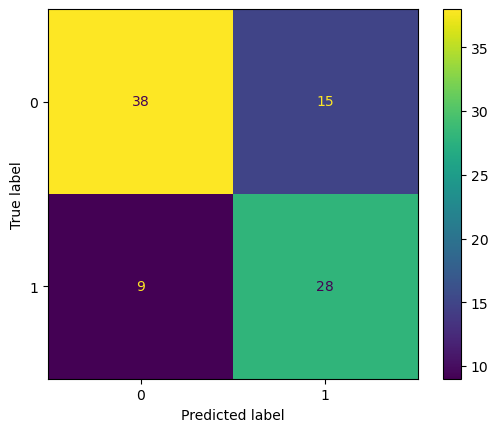

In [11]:
# Let's create and display a confusion matrix for your test data.

# scikit-learn makes it almost laughably easy to show
# a confusion matrix for a classifier that has already been fitted,
# by calling ConfusionMatrixDisplay with its from_estimator method,
# passing it the estimator (i.e. the fitted model), and the
# data you want to use. It will then use the estimator
# to predict the X data, compare the results to the y data
# and, by default, show the actual counts. You can, of course,
# add additional matplotlib code to make it prettier, but 
# it does a very good job using the defaults.

ConfusionMatrixDisplay.from_estimator(bagClf, X_test, y_test)
plt.show()


#### Since we already saw that the model was about 72% correct on the test data, we would expect to see the largest numbers of each row on the main diagonal (upper left to lower right), and we do.


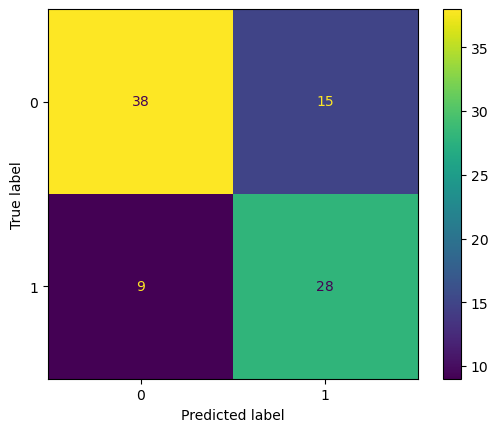

In [12]:
# Task 8, 8 points: another confusion matrix

# 4 points for each of the two lines of code.

# Now you will manually make predictions of the test data, 
# create a confusion matrix manually, and then display it.

# Use the predict method of bagClf, passing it just the X_test
# data as its only argument.  It will predict what it thinks 
# are the correct labels, and you just need to save those predictions
# into the variable y_preds.

y_preds = bagClf.predict(X_test)

# Now call ConfusionMatrixDisplay, but this time use its
# from_predictions method instead of from_estimator in the
# previous cell.  Pass it the ground truth labels, i.e. y_test,
# as its first argument and your new predictions as the second.
# Then call plt.show().  You should see the identical output
# as before.

ConfusionMatrixDisplay.from_predictions(y_test,y_preds)

plt.show() ######## give them this line in the assignment

The random forest's score on the test data is: 0.7666666666666667


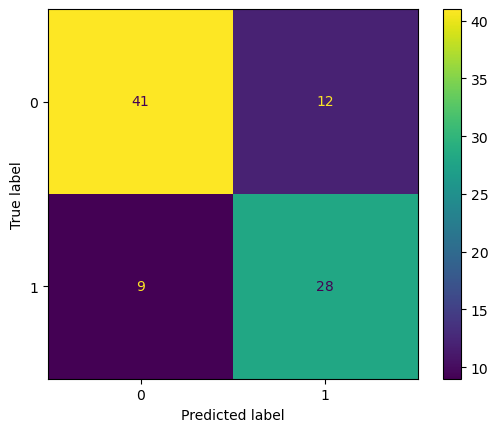

In [13]:
### Task 9, 18 points:  Now create a random forest model
# followed by a confusion matrix.
# You may choose either of the two methods we used above
# for the confusion matrix.

# 6 points: set rfClf to a random forest model
# 4 points each for the other 3 lines of code

# Remember that the only difference between a bagging model
# and random forest is that a random forest considers a 
# a random SUBSET of the predictors at each node split.
# And you will remember when you created the bagging model
# above that you changed the value of max_features from
# its default value of 'sqrt'. So all you have to do is
# use the default value for that hyperparameter, recycling
# all the other hyperparameters from above and you'll get 
# a random forest model.  This should be some EASY points for you.

rfClf = RandomForestClassifier(random_state=34)

# Now fit bagClf on the training data by passing it X_train and y_train.
# There is no need to save the fitted model into a new variable.

rfClf = rfClf.fit(X_train, y_train)

# Now use the fitted model and score it using the test data.
# You simply call the 'score' method of bagClf and pass it 
# the test data, i.e. X_test and y_test

rfScore = rfClf.score(X_test, y_test)

print(f"The random forest's score on the test data is: {rfScore}")

ConfusionMatrixDisplay.from_estimator(rfClf,X_test, y_test)
plt.show()



#### Presumably you just saw that the random forest gets more than an additional 3% of accuracy just by considering fewer predictors at each split. In general, but not always, you'll see a small improvement of random forest over bagging.

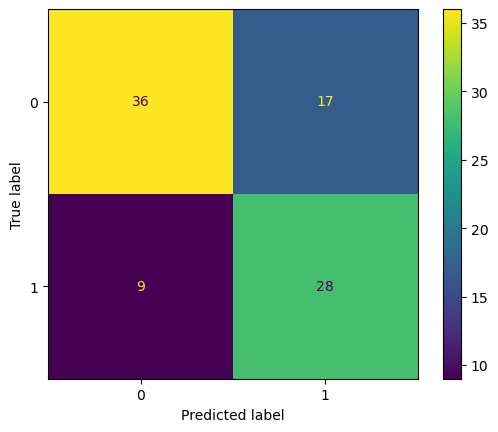

In [14]:
# Extra credit, 3 points: Build a better random forest model

# For example, try a different number of trees, 
# try a different number of predictors at each split,
# or try something else.

rfClf = RandomForestClassifier(n_estimators=120, max_features=8, random_state=43, min_samples_split=13)

# Now fit rfClf on the training data 

rfClf= rfClf.fit(X_train, y_train)

# Now score the model and print the results
 
rfScore = rfClf.score(X_test, y_test)

ConfusionMatrixDisplay.from_estimator(rfClf, X_test, y_test)
plt.show()